# Motion, Momentum and Energy

From straight-line kinematics to circular orbits — interactive visualizations of how objects move, carry momentum, and store energy.

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from ipywidgets import interact, FloatSlider, IntSlider
from matplotlib.patches import Circle
from mpl_toolkits.mplot3d import Axes3D
%matplotlib inline



## Trajectory, Velocity and Acceleration

For one-dimensional motion the three kinematic quantities are linked by differentiation:

$$x(t) \xrightarrow{\frac{d}{dt}} v(t) = \dot{x}(t) \xrightarrow{\frac{d}{dt}} a(t) = \ddot{x}(t)$$

A common example is **uniformly accelerated motion** with $x(t) = \tfrac{1}{2}a_0\,t^2$. Here $v(t) = a_0\,t$ (linear) and $a(t) = a_0$ (constant). Changing the exponent $n$ in $x(t) = \tfrac{1}{2}t^n$ produces different velocity and acceleration profiles:

| $n$ | position | velocity | acceleration |
|---|---|---|---|
| 1 | linear | constant | zero |
| 2 | parabolic | linear | constant |
| 3 | cubic | quadratic | linear |

Use the slider to sweep through exponents and watch all three curves update together.


In [ ]:
@interact(
    n=FloatSlider(min=0.5, max=4, step=0.1, value=2.0, description='Exponent n')
)
def plot_kinematics(n):
    t = np.linspace(0, 10, 300)
    position = 0.5 * t**n
    velocity = np.gradient(position, t)
    acceleration = np.gradient(velocity, t)

    fig, axes = plt.subplots(3, 1, figsize=(8, 7), sharex=True)
    axes[0].plot(t, position, 'b', lw=2)
    axes[0].set_ylabel('Position (m)'); axes[0].set_title(f'x(t) = ½ t^{n:.1f}')
    axes[0].grid(True, alpha=0.3)

    axes[1].plot(t, velocity, 'orange', lw=2)
    axes[1].set_ylabel('Velocity (m/s)')
    axes[1].grid(True, alpha=0.3)

    axes[2].plot(t, acceleration, 'green', lw=2)
    axes[2].set_ylabel('Acceleration (m/s²)'); axes[2].set_xlabel('Time (s)')
    axes[2].grid(True, alpha=0.3)

    plt.tight_layout()
    plt.show()


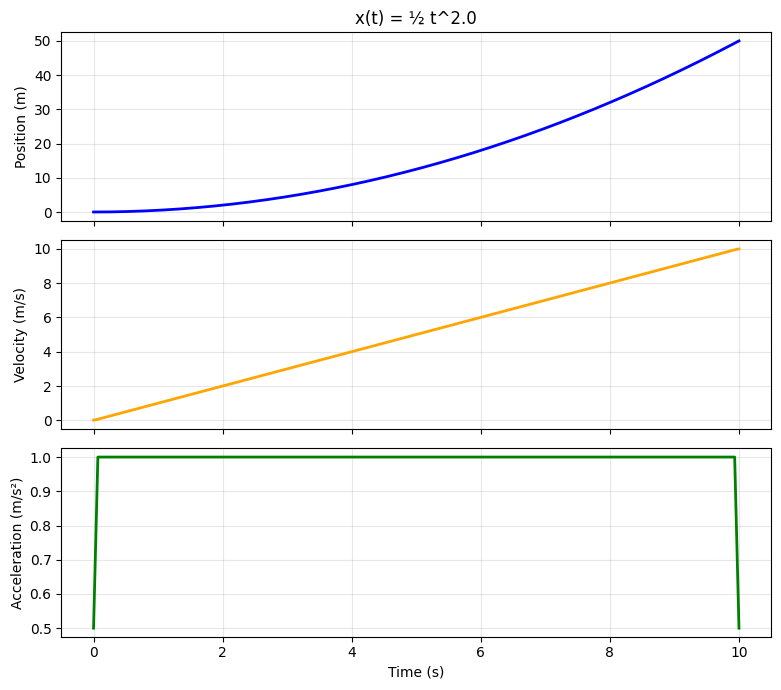

In [ ]:
# Hero figure — the one static image this notebook shows on GitHub.
plot_kinematics(n=(FloatSlider(min=0.5, max=4, step=0.1, value=2.0, description='Exponent n')).value)


## Linear Momentum

The **momentum** of an object is

$$\vec{p} = m\,\vec{v}$$

Momentum is a vector pointing in the direction of velocity. Newton's second law can be restated as $\vec{F}_{\text{net}} = \frac{d\vec{p}}{dt}$: a net force changes momentum over time. In the absence of external forces, total momentum is **conserved** — the foundation of collision analysis.

For a fixed mass of $10\;\text{kg}$, increasing speed proportionally increases momentum.


In [ ]:
@interact(
    velocity=FloatSlider(min=-10, max=10, step=0.5, value=4, description='v (m/s)')
)
def plot_momentum(velocity):
    mass = 10
    p = mass * velocity

    fig, ax = plt.subplots(figsize=(7, 3.5))
    ax.add_patch(plt.Rectangle((-1.5, -1), 3, 2, color='lightgray', ec='black'))
    ax.annotate(f'{mass} kg', (0, 0), ha='center', va='center', fontsize=11)
    if abs(velocity) > 0.1:
        ax.arrow(0, 0, velocity*0.8, 0, head_width=0.3, head_length=0.3, fc='red', ec='red', lw=1.5)
    ax.set_xlim(-12, 12); ax.set_ylim(-3, 3)
    ax.set_aspect('equal')
    ax.set_xlabel('X (m)')
    ax.set_title(f'p = m·v = {mass}×{velocity:.1f} = {p:.1f} kg·m/s')
    ax.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()



## Kinetic Energy

The kinetic energy of a body of mass $m$ moving at speed $v$ is

$$K = \frac{1}{2}\,m\,v^2$$

Unlike momentum, kinetic energy is a **scalar** and always non-negative. Because of the $v^2$ dependence, doubling speed quadruples kinetic energy — which is why high-speed impacts are so much more destructive. The **work–energy theorem** links the two concepts: the net work done on an object equals the change in its kinetic energy.


In [ ]:
@interact(
    velocity=FloatSlider(min=0, max=10, step=0.5, value=4, description='v (m/s)')
)
def plot_kinetic(velocity):
    mass = 10
    KE = 0.5 * mass * velocity**2

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(9, 3.5), gridspec_kw={'width_ratios': [1, 1.2]})

    # Left: object + velocity arrow
    ax1.add_patch(plt.Rectangle((-1.5, -1), 3, 2, color='lightgray', ec='black'))
    if velocity > 0.1:
        ax1.arrow(0, 0, velocity*0.7, 0, head_width=0.3, head_length=0.3, fc='red', ec='red', lw=1.5)
    ax1.annotate(f'{mass} kg', (0, 0), ha='center', va='center', fontsize=11)
    ax1.set_xlim(-8, 10); ax1.set_ylim(-3, 3); ax1.set_aspect('equal')
    ax1.set_title(f'v = {velocity:.1f} m/s')
    ax1.grid(True, alpha=0.3)

    # Right: KE vs v curve
    v_arr = np.linspace(0, 10, 100)
    ax2.plot(v_arr, 0.5*mass*v_arr**2, 'b-', lw=2)
    ax2.plot(velocity, KE, 'ro', ms=10, zorder=5)
    ax2.set_xlabel('v (m/s)'); ax2.set_ylabel('K (J)')
    ax2.set_title(f'K = ½mv² = {KE:.1f} J')
    ax2.grid(True, alpha=0.3)

    plt.tight_layout()
    plt.show()



## Gravitational Potential Energy

Near Earth's surface, lifting an object of mass $m$ to a height $h$ stores gravitational potential energy

$$U = m\,g\,h$$

This energy can be fully recovered: a falling object converts $U$ back into kinetic energy ($K$). The principle of **conservation of mechanical energy** states that, in the absence of non-conservative forces (friction, drag):

$$K + U = \text{const}$$

Below, raise the blue ball and watch the stored potential energy grow.


In [ ]:
@interact(
    height=FloatSlider(min=0, max=7, step=0.2, value=3, description='h (m)')
)
def plot_potential(height):
    mass, g = 10, 9.81
    PE = mass * g * height

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(9, 4.5), gridspec_kw={'width_ratios': [0.6, 1]})

    ax1.plot(0, height, 'o', ms=18, color='royalblue')
    ax1.plot([0, 0], [0, height], 'g--', lw=1.5)
    ax1.axhline(0, color='brown', lw=2, label='Ground')
    ax1.annotate(f'h = {height:.1f} m', xy=(0.3, height/2), fontsize=10, color='green')
    ax1.set_xlim(-2, 2); ax1.set_ylim(-1, 8)
    ax1.set_ylabel('Height (m)')
    ax1.set_title(f'U = mgh = {PE:.1f} J')
    ax1.legend(fontsize=9); ax1.grid(True, alpha=0.3)

    h_arr = np.linspace(0, 7, 100)
    ax2.plot(h_arr, mass*g*h_arr, 'b-', lw=2)
    ax2.plot(height, PE, 'ro', ms=10, zorder=5)
    ax2.set_xlabel('h (m)'); ax2.set_ylabel('U (J)')
    ax2.set_title('Potential Energy vs Height')
    ax2.grid(True, alpha=0.3)

    plt.tight_layout()
    plt.show()



## Uniform Circular Motion

An object moving in a circle of radius $r$ at constant speed $v$ has:

- **Tangential velocity** $\vec{v}$: always tangent to the circle, magnitude $v = \omega r$.
- **Centripetal acceleration** $\vec{a}_c$: directed toward the centre, magnitude $a_c = \frac{v^2}{r} = \omega^2 r$.
- **Angular velocity** $\vec{\omega}$: perpendicular to the plane of motion (right-hand rule).

Even though the speed is constant, the direction of $\vec{v}$ changes continuously — that is what requires the centripetal force $F_c = m\,a_c$.


In [ ]:
@interact(
    pos=FloatSlider(min=0, max=1, step=0.02, value=0.15, description='Position')
)
def plot_circular(pos):
    theta = pos * 2 * np.pi
    r = 1
    sx, sy = r*np.cos(theta), r*np.sin(theta)

    fig, ax = plt.subplots(figsize=(5.5, 5.5))
    circle_t = np.linspace(0, 2*np.pi, 200)
    ax.plot(r*np.cos(circle_t), r*np.sin(circle_t), color='lightgray', lw=1.5)
    ax.plot(sx, sy, 'o', ms=12, color='royalblue', zorder=5)

    # Centripetal (toward centre)
    ax.arrow(sx, sy, -sx*0.35, -sy*0.35, head_width=0.04, head_length=0.03, fc='red', ec='red', lw=1.5, label='Centripetal F')

    # Tangent direction (counter-clockwise)
    tx, ty = -np.sin(theta), np.cos(theta)
    ax.arrow(sx, sy, tx*0.5, ty*0.5, head_width=0.04, head_length=0.03, fc='green', ec='green', lw=1.5, label='Tangential v')

    ax.plot(0, 0, 'k+', ms=10, mew=2)
    ax.set_xlim(-1.6, 1.6); ax.set_ylim(-1.6, 1.6)
    ax.set_aspect('equal')
    ax.set_title(f'θ = {np.rad2deg(theta):.0f}°')
    ax.legend(fontsize=9, loc='upper left')
    ax.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()



## Angular Momentum

For a rigid body rotating with angular velocity $\omega$ about a fixed axis, the **angular momentum** is

$$L = I\,\omega$$

where $I$ is the moment of inertia. As a vector, $\vec{L} = I\,\vec{\omega}$, pointing along the rotation axis (right-hand rule). Angular momentum is conserved when no external torque acts — this explains why a spinning ice-skater speeds up when pulling in their arms (reducing $I$ raises $\omega$ to keep $L$ constant).

Adjust the moment of inertia and angular velocity below; the black arrow shows $\vec{\omega}$ and the red arrow shows $\vec{L}$.


In [ ]:
@interact(
    I=FloatSlider(min=0.5, max=10, step=0.5, value=2, description='Inertia I'),
    omega=FloatSlider(min=0.5, max=10, step=0.5, value=3, description='ω (rad/s)')
)
def plot_angular_momentum(I, omega):
    L = I * omega

    fig = plt.figure(figsize=(6, 5.5))
    ax = fig.add_subplot(111, projection='3d')
    theta = np.linspace(0, 2*np.pi, 100)
    ax.plot(3*np.cos(theta), 3*np.sin(theta), np.zeros_like(theta), color='lightgray', lw=1.5)
    t = omega * 0.5  # sample position
    ax.scatter(3*np.cos(t), 3*np.sin(t), 0, color='royalblue', s=80, label='Object')
    ax.quiver(0, 0, 0, 0, 0, omega, color='k', arrow_length_ratio=0.1, lw=2, label=f'ω = {omega:.1f}')
    ax.quiver(0, 0, 0, 0, 0, L, color='r', arrow_length_ratio=0.08, lw=2.5, label=f'L = Iω = {L:.1f}')
    ax.set_xlabel('X'); ax.set_ylabel('Y'); ax.set_zlabel('Z')
    ax.set_xlim(-8, 8); ax.set_ylim(-8, 8); ax.set_zlim(-1, max(L+1, omega+1, 5))
    ax.set_title(f'Angular Momentum  L = {I:.1f} × {omega:.1f} = {L:.1f} kg·m²/s')
    ax.legend(fontsize=8, loc='upper left')
    plt.tight_layout()
    plt.show()
